<a href="https://colab.research.google.com/github/gi-junqueira/Calculo-Numerico/blob/main/Atividade_gauss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Atividade Gauss

#Resolução da 5, 6 e 7

Feito por Giovanna Maria de Siqueira Junqueira          
RA: 185218

k    | x^(k)      | y^(k)      | z^(k)      | Erro (Linf) 
----------------------------------------------------------
0    | 0.000000   | 0.000000   | 0.000000   | -           
1    | 0.600000   | 2.054545   | -0.914545  | 2.054545e+00
2    | 0.988364   | 2.006711   | -0.997002  | 3.883636e-01
3    | 1.000071   | 2.000279   | -0.999986  | 1.170777e-02
4    | 1.000025   | 2.000004   | -1.000005  | 2.755404e-04
5    | 1.000001   | 2.000000   | -1.000000  | 2.389216e-05
6    | 1.000000   | 2.000000   | -1.000000  | 1.262607e-06

--- RESULTADO FINAL ---
Número de iterações: 6
Solução aproximada: x = 1.000000, y = 2.000000, z = -1.000000


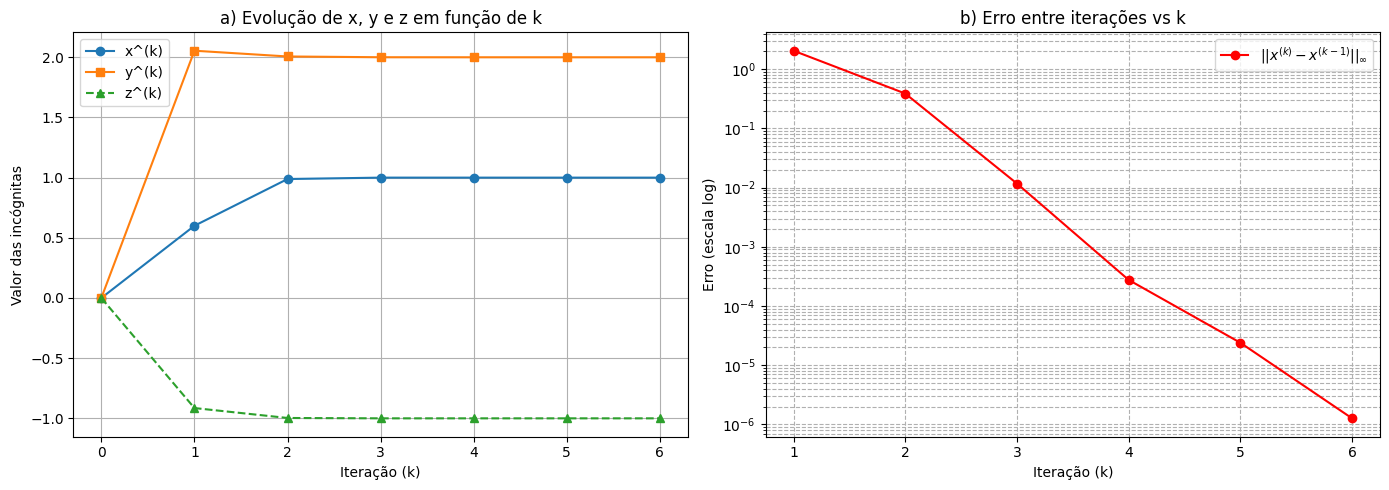

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Definindo Ax = b
A = np.array([[10.0, -1.0, 2.0], [-1.0, 11.0, -1.0], [2.0, -1.0, 10.0]])

b = np.array([6.0, 22.0, -10.0])

# Dados iniciais
x = np.array([0.0, 0.0, 0.0])
tol = 1e-5
max_iter = 100

# Armazenar resultados
historico_x = [x.copy()]
erros = []
tabela = []

print(f"{'k':<4} | {'x^(k)':<10} | {'y^(k)':<10} | {'z^(k)':<10} | {'Erro (Linf)':<12}")
print("-" * 58)

k = 0

tabela.append([0, x[0], x[1], x[2], "-"] )
print(f"{0:<4} | {x[0]:<10.6f} | {x[1]:<10.6f} | {x[2]:<10.6f} | {'-':<12}")

while k < max_iter:
  x_old = x.copy()

  # Fórmula de Gauss-Seidel
  x[0] = (6.0 + x[1] - 2.0 * x[2]) / 10.0
  x[1] = (22.0 + x[0] + x[2]) / 11.0
  x[2] = (-10.0 - 2.0 * x[0] + x[1]) / 10.0

  k += 1
  erro = np.max(np.abs(x - x_old))

  historico_x.append(x.copy())
  erros.append(erro)
  tabela.append([k, x[0], x[1], x[2], erro])

  print(
      f"{k:<4} | {x[0]:<10.6f} | {x[1]:<10.6f} | {x[2]:<10.6f} | {erro:<12.6e}"
  )

  if erro < tol:
    break

historico_x = np.array(historico_x)

print("\n--- RESULTADO FINAL ---")
print(f"Número de iterações: {k}")
print(f"Solução aproximada: x = {x[0]:.6f}, y = {x[1]:.6f}, z = {x[2]:.6f}")

# GRÁFICOS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


iters = range(len(historico_x))
ax1.plot(iters, historico_x[:, 0], 'o-', label='x^(k)')
ax1.plot(iters, historico_x[:, 1], 's-', label='y^(k)')
ax1.plot(iters, historico_x[:, 2], '^--', label='z^(k)')
ax1.set_xlabel('Iteração (k)')
ax1.set_ylabel('Valor das incógnitas')
ax1.set_title('a) Evolução de x, y e z em função de k')
ax1.grid(True)
ax1.legend()


ax2.semilogy(range(1, k + 1), erros, 'ro-', label=r'$||x^{(k)} - x^{(k-1)}||_{\infty}$')
ax2.set_xlabel('Iteração (k)')
ax2.set_ylabel('Erro (escala log)')
ax2.set_title('b) Erro entre iterações vs k')
ax2.grid(True, which='both', ls='--')
ax2.legend()

plt.tight_layout()
plt.show()